# Colatron — demo notebook (Team 23)
Data → pipeline → reproduction (SVR/NN/Seq2Seq) → extension (DCTTS) → results, with inline audio. Run top-to-bottom after `python main.py --all`.

In [1]:
import os, sys, json, numpy as np
sys.path.insert(0, os.path.abspath('..'))
from src import config as C, audio as A
from IPython.display import Audio, display, Image
print('sr', C.SR, 'n_fft', C.N_FFT, 'hop', C.HOP, 'win', C.WIN)

sr 20000 n_fft 2048 hop 250 win 1000


## 1. Data split & front-end

In [2]:
for name in ['train','dev','test']:
    ids=open(f'../data/splits/{name}.txt').read().split()
    print(name, len(ids), 'e.g.', ids[:2])

train 200 e.g. ['LJ002-0193', 'LJ004-0145']
dev 25 e.g. ['LJ005-0096', 'LJ005-0044']
test 25 e.g. ['LJ001-0083', 'LJ003-0137']


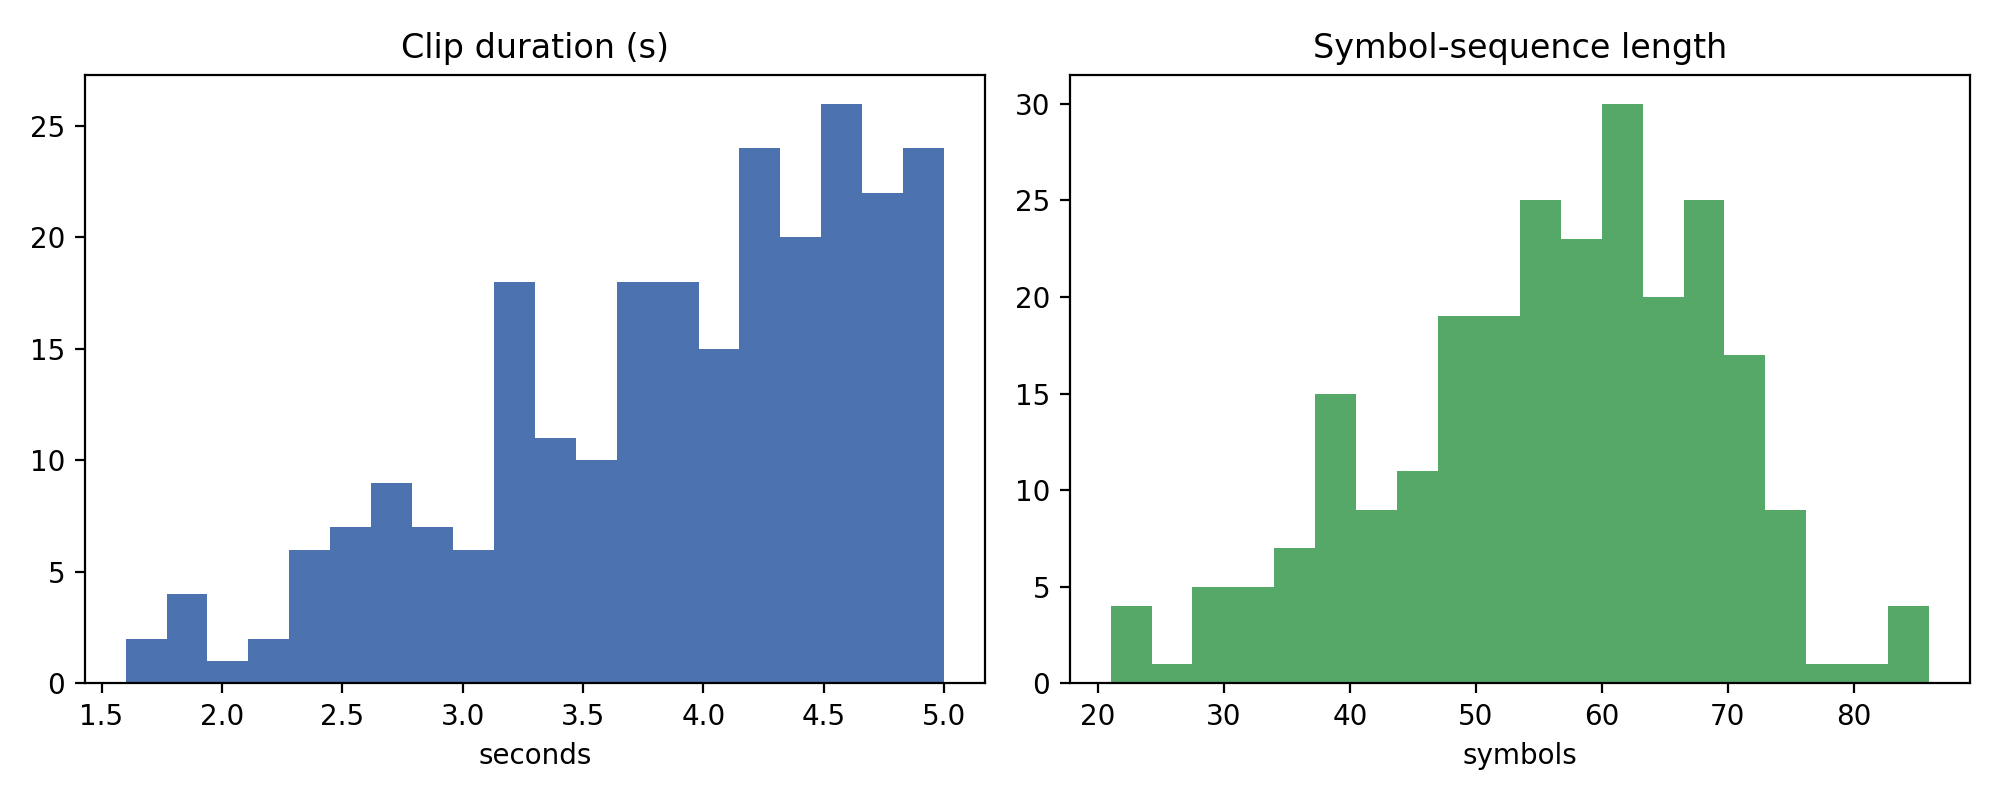

In [3]:
# EDA figure
display(Image('../results/figures/eda.png'))

## 2. Vocoder ceiling (GT → STFT → Griffin-Lim)

In [4]:
import glob
gt=sorted(glob.glob('../results/audio/gt_recon/*.gt.wav'))[:1]
gl=sorted(glob.glob('../results/audio/gt_recon/*.gl.wav'))[:1]
print('ground truth:'); display(Audio(gt[0]))
print('Griffin-Lim reconstruction (the ceiling):'); display(Audio(gl[0]))

ground truth:


Griffin-Lim reconstruction (the ceiling):


## 3. Reproduction & extension — listen to one test sentence per model

In [5]:
tid=open('../data/splits/test.txt').read().split()[0]; print('clip', tid)
for m in ['ground_truth','svr','nn','seq2seq','dctts']:
    p=f'../results/audio/{m}/{tid}.wav'
    if os.path.exists(p):
        print(m); display(Audio(p))

clip LJ001-0083
ground_truth


svr


nn


seq2seq


dctts


## 4. Spectrograms & attention

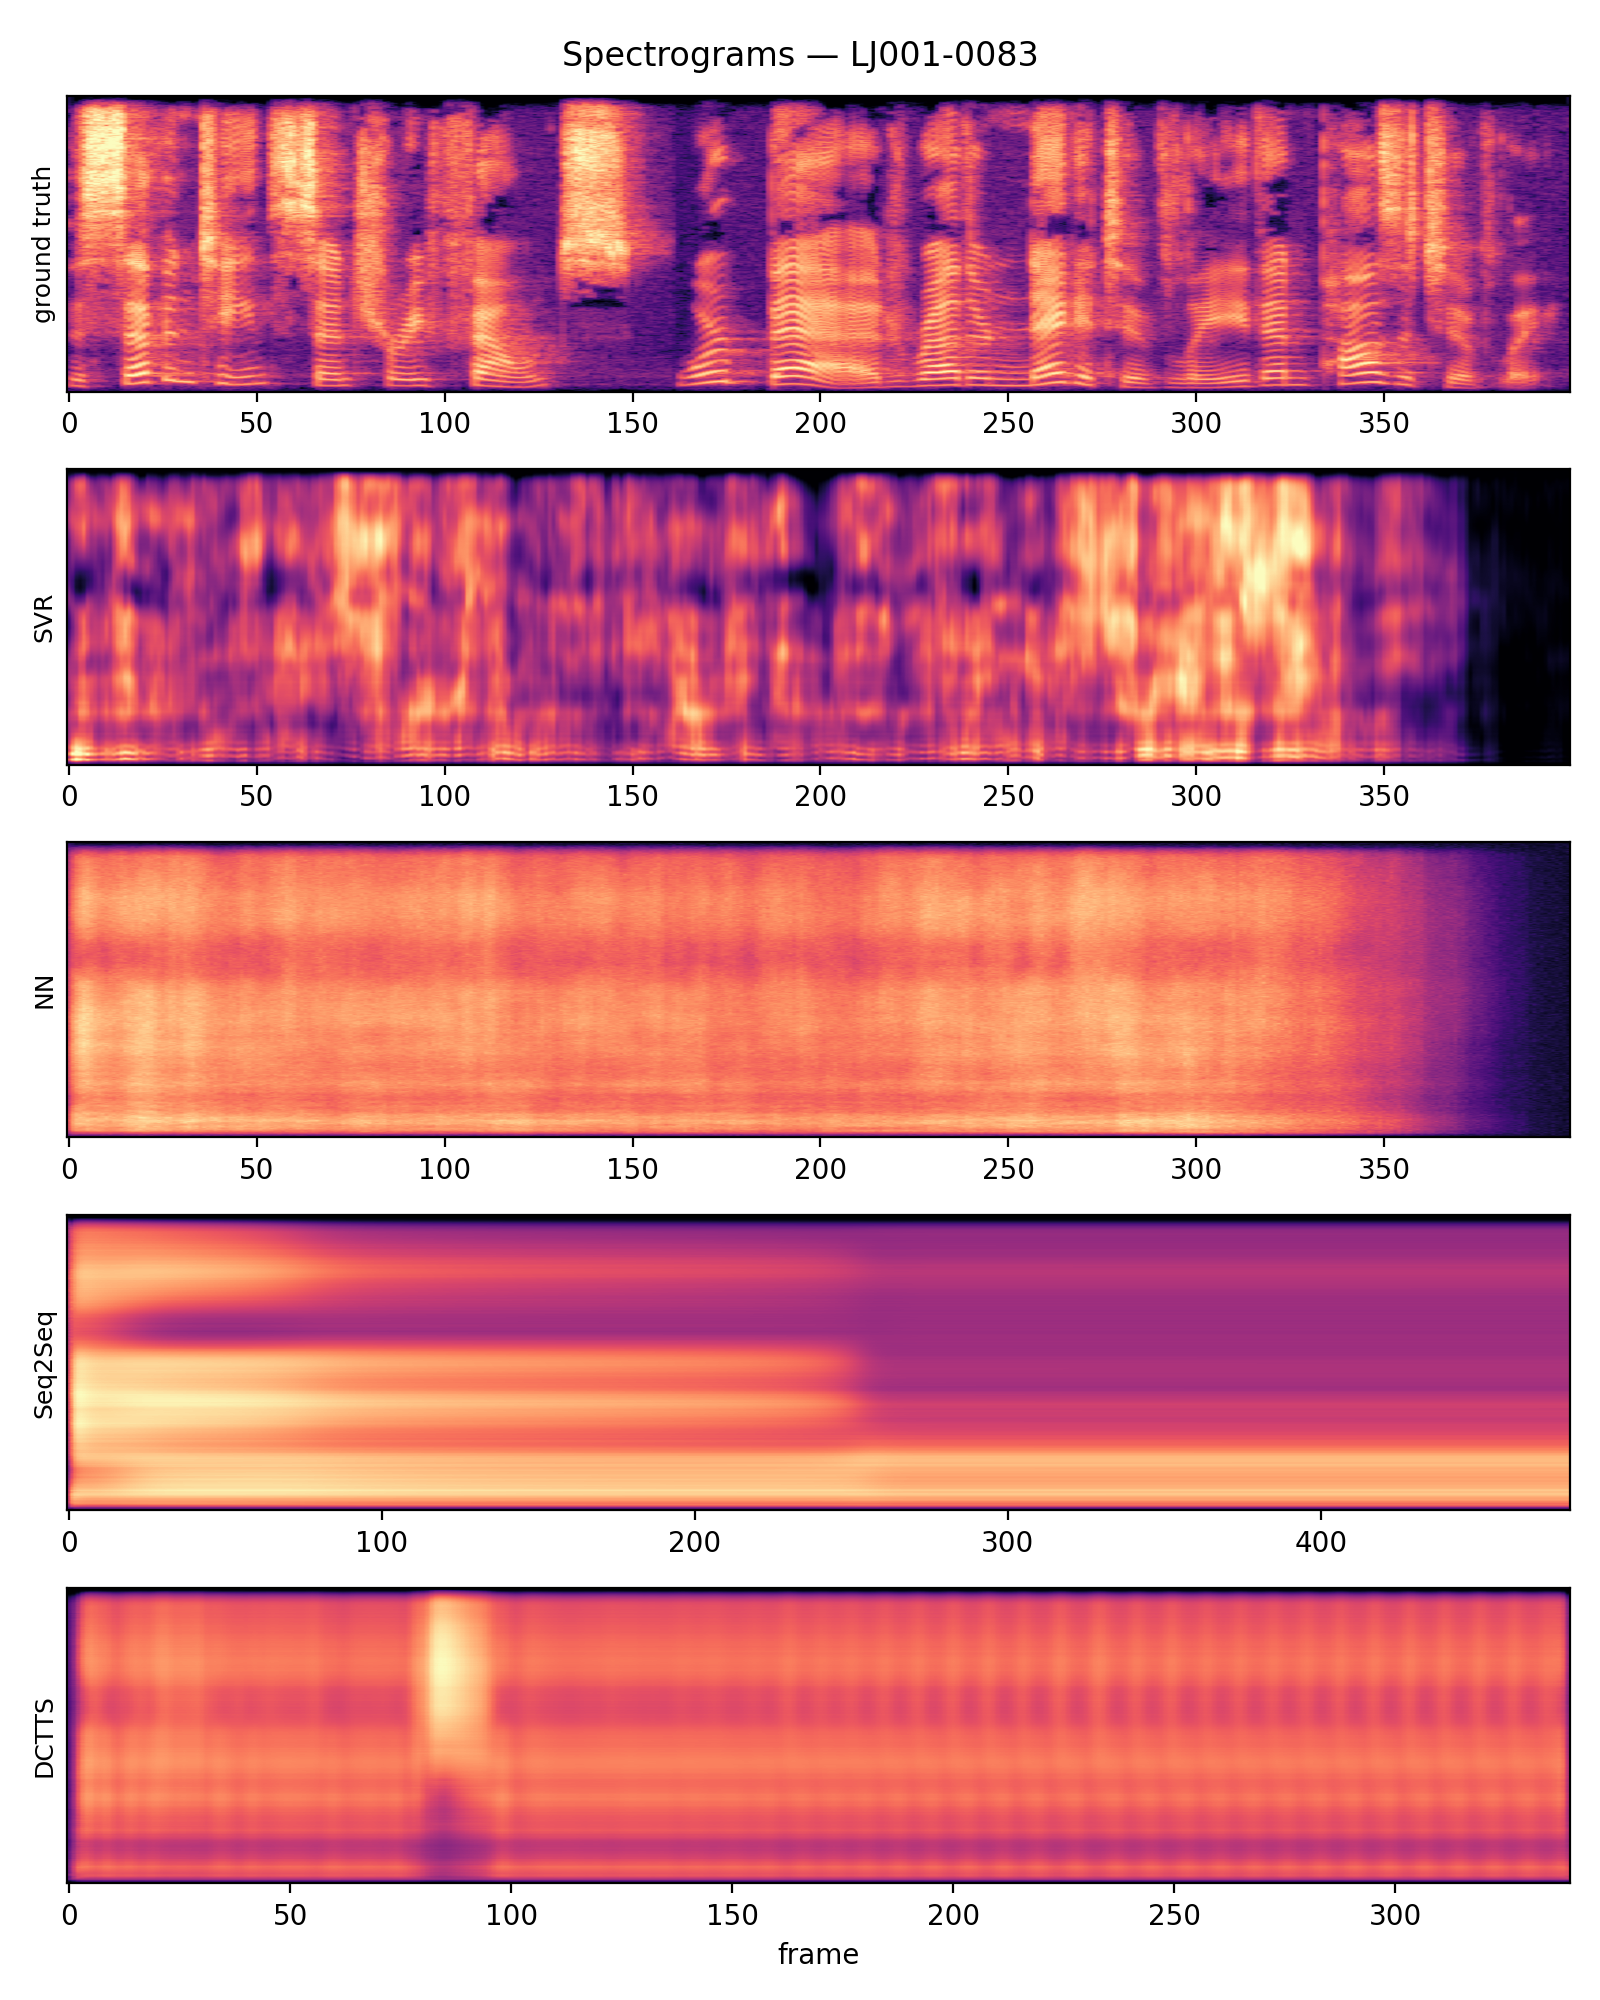

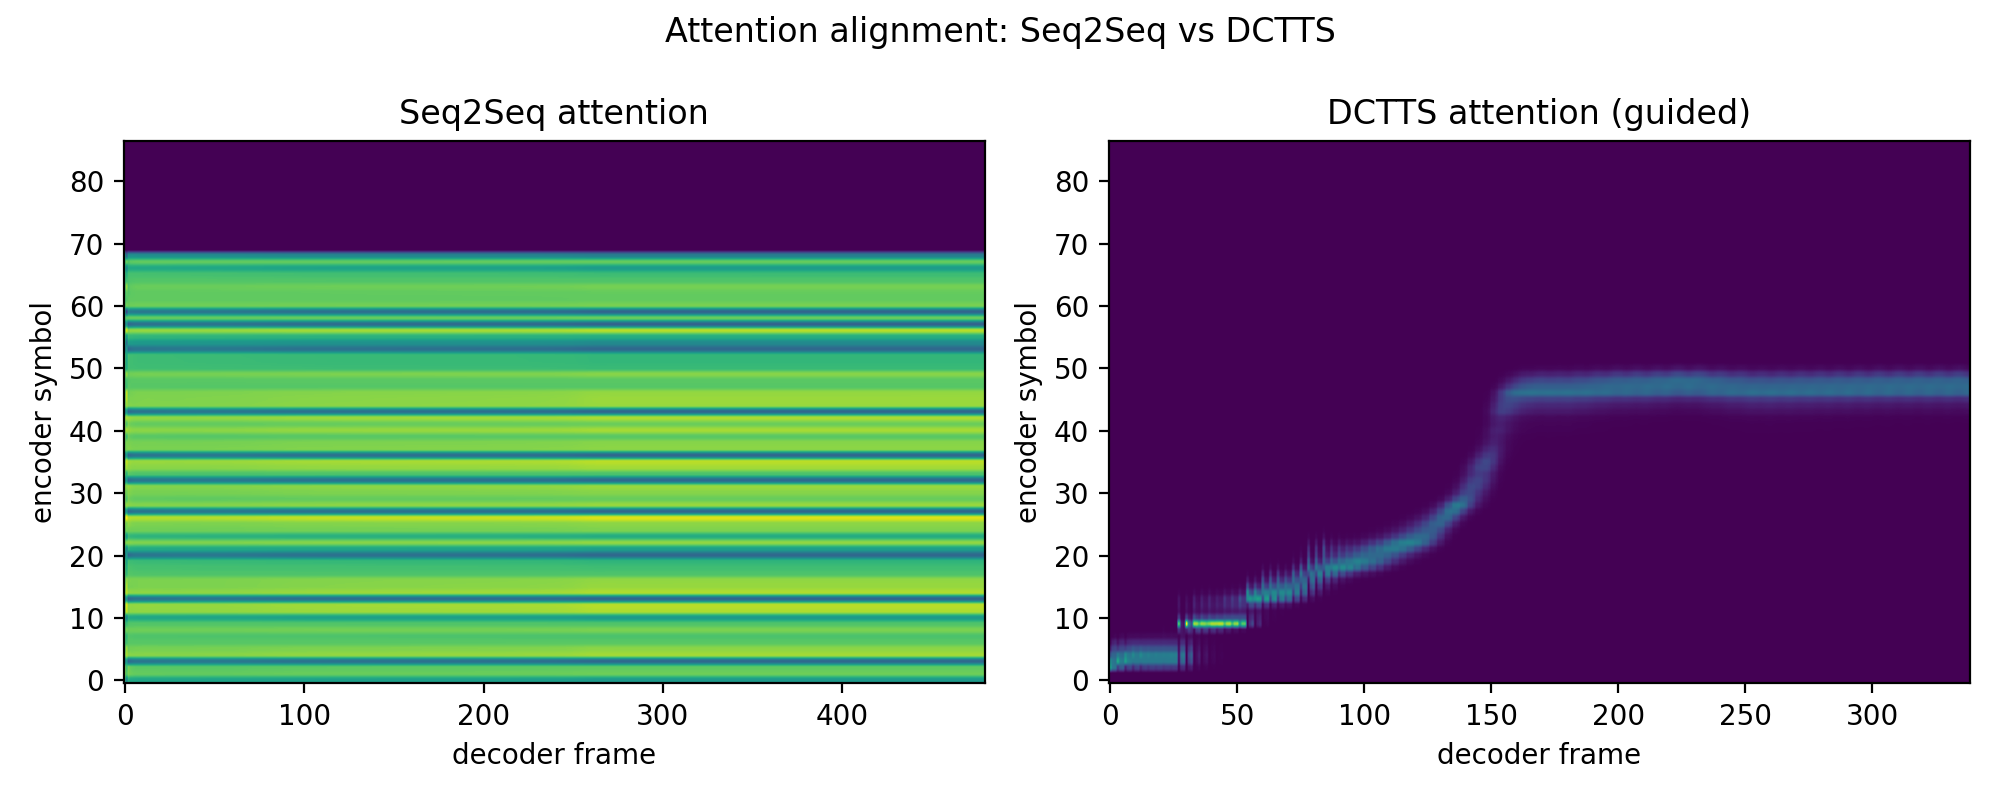

In [6]:
display(Image('../results/figures/spectrograms.png'))
display(Image('../results/figures/attention_compare.png'))

## 5. Results table

In [7]:
print(open('../results/comparison_table.md',encoding='utf-8').read())

# Reported vs Ours — Colatron reproduction + DCTTS extension

Human MOS (paper) is from 10 Stanford raters (Table 2). Our primary automated stand-in is **UTMOS** (predicted MOS); a small human MOS test is optional and reported only if collected. All objective metrics are on the 25 held-out test clips. Lower MCD/CER/WER/specL1 = better; higher UTMOS = better.

| Model | Reported MOS (paper) | Our UTMOS | Our human MOS | MCD | CER | WER | spec L1 |
|---|---|---|---|---|---|---|---|
| Ground truth (ref) | — | 4.34 | — | 0.05 | 0.040 | 0.052 | — |
| GT + Griffin-Lim (vocoder ceiling, ref) | — | 3.01 | — | 23.16 | 0.041 | 0.055 | — |
| SVR (poly) | 1.0 | 1.31 | pending | 42.41 | 0.834 | 0.985 | 0.1612 |
| SVR (linear) | — | 1.30 | — | 53.03 | 0.891 | 0.993 | 0.2130 |
| Simple NN | 1.7 | 1.39 | pending | 40.99 | 0.934 | 0.996 | 0.1570 |
| Seq2Seq + attention | 2.5 | 1.63 | pending | 51.34 | 0.929 | 0.996 | 0.1689 |
| DCTTS (extension) | — | 1.44 | pending | 51.44 | 0.915 | 1.000 | 0.1886 |



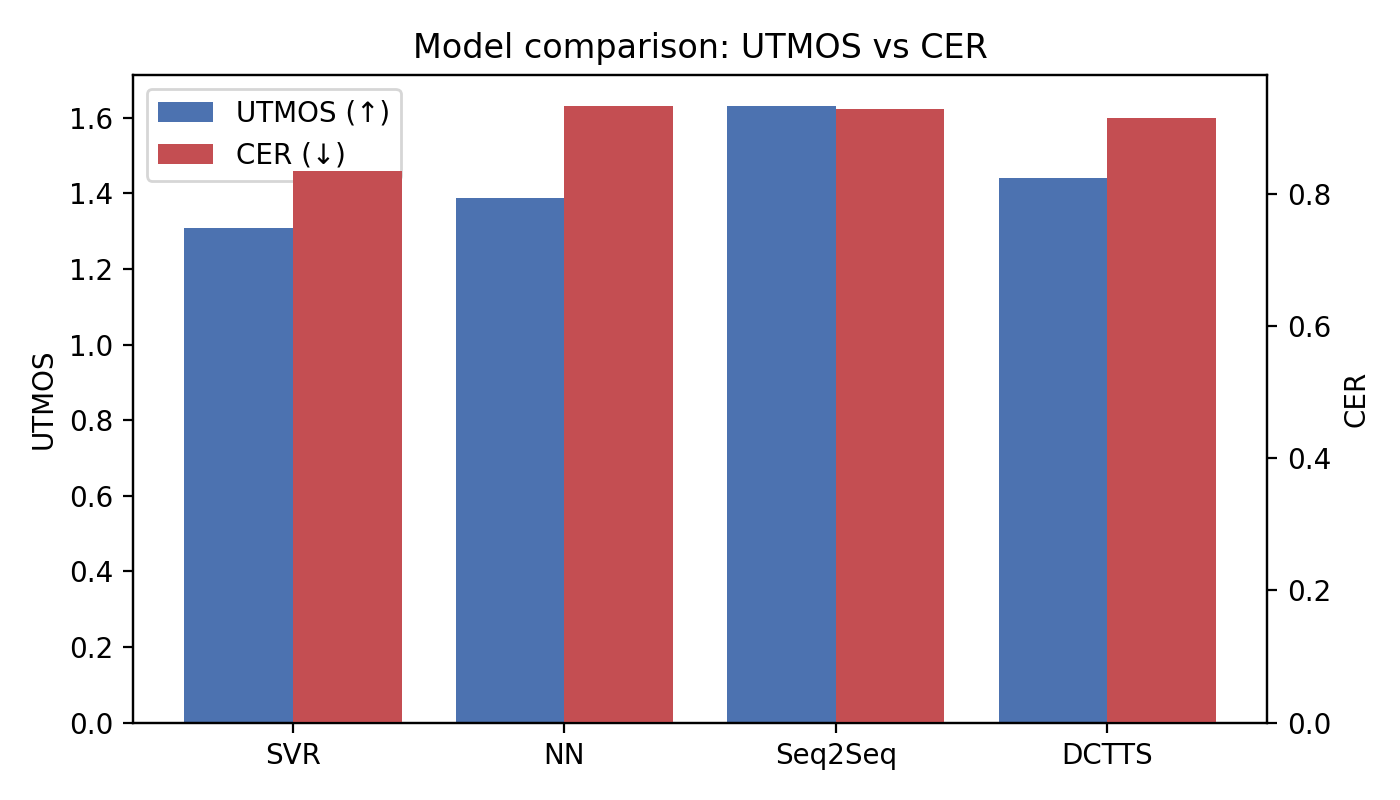

In [8]:
display(Image('../results/figures/compare_bars.png'))